# Maman 13 - Deep Learning 
**Name:** Lian Sigawi  
**ID:** 318814746


## Question 1: Custom 2D Convolutional Layer

In this section, we implement a custom 2D convolution operation from scratch, inheriting from `nn.Module`. 

### Key Features:
* **Custom Initialization:** Defining learnable weights and biases as `nn.Parameter`.
* **Spatial Logic:** Implementation of the cross-correlation forward pass, including support for:
    * **Padding:** Symmetric zero-padding to the input boundaries.
    * **Stride:** Efficient sliding window traversal across spatial dimensions.
* **Validation:** Verification of numerical correctness by comparing the custom output against the official `nn.Conv2d` implementation using a sanity check.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MyConv2d(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, kernel_size=(1, 1), stride=1, padding=0):
        super(MyConv2d, self).__init__()
        
        # Store basic parameters
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size if isinstance(kernel_size, tuple) else (kernel_size, kernel_size)
        self.stride = stride
        self.padding = padding
        
        # Initialize filters (weights) and biases as learnable parameters
        self.weight = nn.Parameter(torch.randn(out_channels, in_channels, self.kernel_size[0], self.kernel_size[1]))
        
        # Initialize learnable bias
        self.bias = nn.Parameter(torch.randn(out_channels))

    def forward(self, x):
        # We will implement the convolution logic here in the next step
        pass

In [ ]:
import torch
import torch.nn as nn

class MyConv2d(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, kernel_size=(1, 1), stride=1, padding=0):
        super(MyConv2d, self).__init__()
        
        # Initialize basic parameters
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size if isinstance(kernel_size, tuple) else (kernel_size, kernel_size)
        self.stride = stride
        self.padding = padding
        
        # Initialize learnable weights and bias
        # Weight shape: [out_channels, in_channels, k_h, k_w]
        self.weight = nn.Parameter(torch.randn(out_channels, in_channels, self.kernel_size[0], self.kernel_size[1]))
        self.bias = nn.Parameter(torch.randn(out_channels))

    def forward(self, x):
        """
        Performs the 2D convolution operation.
        Input x shape: [batch_size, in_channels, height, width]
        """
        batch_size, in_c, in_h, in_w = x.shape
        k_h, k_w = self.kernel_size
        
        # Apply padding to the input tensor
        # padding_config is (padding_left, padding_right, padding_top, padding_bottom)
        if self.padding > 0:
            x_padded = torch.nn.functional.pad(x, (self.padding, self.padding, self.padding, self.padding))
        else:
            x_padded = x
            
        # Update padded dimensions
        _, _, pad_h, pad_w = x_padded.shape
        
        # Calculate output dimensions based on the formula
        out_h = int((in_h + 2 * self.padding - k_h) / self.stride) + 1
        out_w = int((in_w + 2 * self.padding - k_w) / self.stride) + 1
        
        # Initialize the output tensor with zeros
        output = torch.zeros(batch_size, self.out_channels, out_h, out_w).to(x.device)
        
        # Perform the convolution using a sliding window
        for i in range(out_h):
            for j in range(out_w):
                # Calculate the current window's starting position
                h_start = i * self.stride
                h_end = h_start + k_h
                w_start = j * self.stride
                w_end = w_start + k_w
                
                # Slice the local patch from the input: [batch_size, in_channels, k_h, k_w]
                patch = x_padded[:, :, h_start:h_end, w_start:w_end]
                
                # Multiply patch by all filters and sum over in_channels, k_h, and k_w
                # We use unsqueeze to align dimensions for broadcasting
                # output[:, oc, i, j] = sum(patch * weight[oc]) + bias[oc]
                for oc in range(self.out_channels):
                    output[:, oc, i, j] = torch.sum(patch * self.weight[oc], dim=(1, 2, 3)) + self.bias[oc]
                    
        return output

In [3]:
# Create test parameters
in_c, out_c = 3, 16
k_size = (3, 3)
stride = 2
padding = 1

# Initialize both layers
my_layer = MyConv2d(in_channels=in_c, out_channels=out_c, kernel_size=k_size, stride=stride, padding=padding)
official_layer = nn.Conv2d(in_channels=in_c, out_channels=out_c, kernel_size=k_size, stride=stride, padding=padding)

# Copy weights and bias from MyConv2d to nn.Conv2d to ensure identical parameters
with torch.no_grad():
    official_layer.weight.copy_(my_layer.weight)
    official_layer.bias.copy_(my_layer.bias)

# Create a random input tensor: [batch_size, channels, height, width]
test_input = torch.randn(2, in_c, 32, 32)

# Get outputs from both layers
my_output = my_layer(test_input)
official_output = official_layer(test_input)

# Compare results
# We use torch.allclose to allow for very small numerical differences due to floating point precision
diff = torch.abs(my_output - official_output).max().item()
is_correct = torch.allclose(my_output, official_output, atol=1e-5)

print(f"Max absolute difference: {diff}")
print(f"Are the outputs identical? {is_correct}")

Max absolute difference: 5.7220458984375e-06
Are the outputs identical? True


## Question 2: Theoretical Analysis

The theoretical solution for Question 2, including the required derivations and analysis, is provided below as a handwritten document.


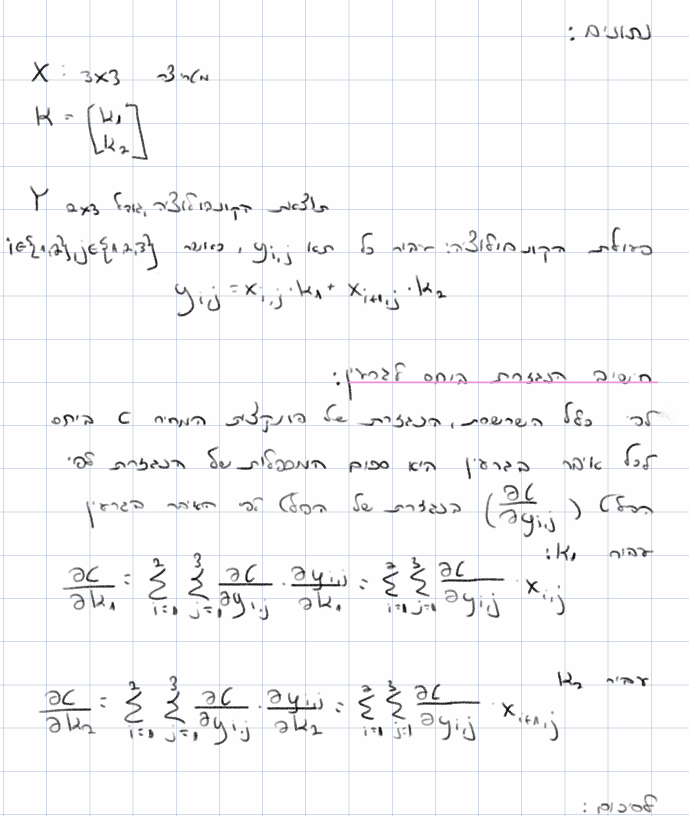

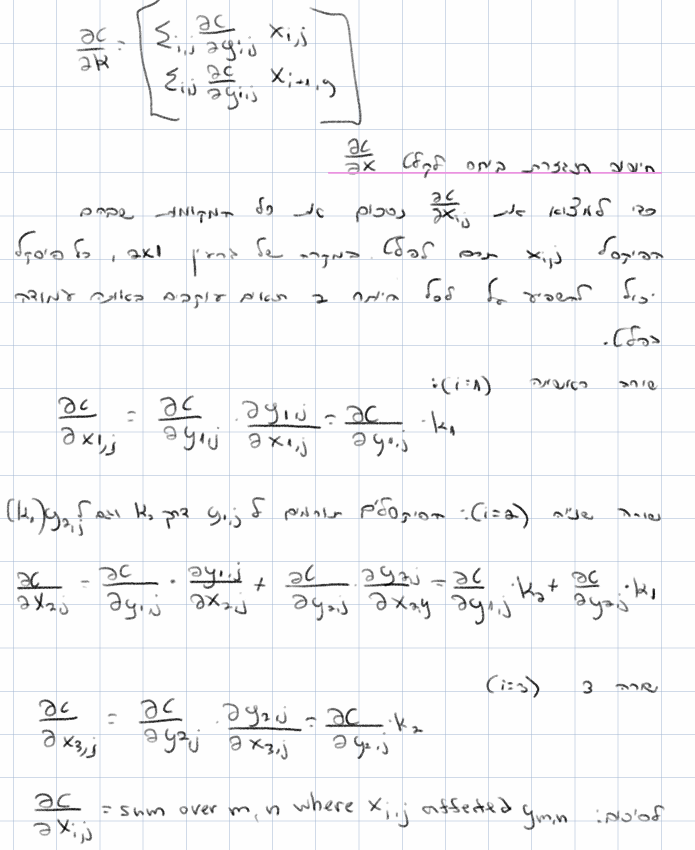

## Question 3: Transfer Learning and Custom ResNet

In this question, we explore image classification on the CIFAR-10 dataset using two approaches: fine-tuning a pre-trained ResNet18 model and training a custom-built ResNet architecture from scratch.

### Part A-C: Data Loading and Visualization
We begin by initializing the CIFAR-10 dataset. Initially, a basic transformation is applied to visualize the raw samples and verify the data integrity.

Labels: frog  horse cat   deer  cat  


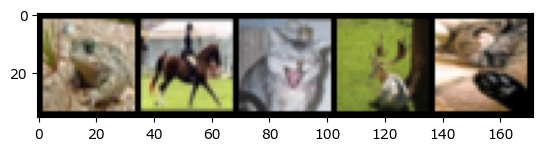

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Sectuon A: Dataset Initialization
transform_basic = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, 
                                             download=True, transform=transform_basic)

# CIFAR-10 category labels
classes = ('plane', 'car', 'bird', 'cat', 'deer', 
           'dog', 'frog', 'horse', 'ship', 'truck')

# Section C: Data Visualization
def imshow(img):
    npimg = img.numpy()
    # Transpose dimensions to match Matplotlib requirements
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Initialize a DataLoader to fetch a small batch for inspection
trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=5, shuffle=True)
dataiter = iter(trainloader)
images, labels = next(dataiter)

print('Labels:', ' '.join(f'{classes[labels[j]]:5s}' for j in range(5)))
imshow(torchvision.utils.make_grid(images))

### Part D-I: Transfer Learning with Pre-trained ResNet18
To leverage power of transfer learning, we adapt a pre-trained ResNet18 model:
* **Preprocessing:** Resizing to 224x224 and applying ImageNet-standard normalization.
* **Feature Extraction:** Freezing the convolutional backbone and replacing the final FC layer.
* **Optimization:** Training only the new head using Adam optimizer.
* **Qualitative Analysis:** Identifying "Confident Mistakes" to visualize instances where the model predicted an incorrect label with high probability.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import models
from torch.utils.data import DataLoader

# Hardware acceleration setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- Section F (Guideline 1): ResNet-specific transformations ---
# ResNet models require 224x224 input and specific mean/std normalization
transform_train = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # נרמול לפי הנחיות המטלה
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Reloading datasets with updated transformations
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

# --- Section D: Loading Pre-trained ResNet18 ---
try:
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
except AttributeError:
    model = models.resnet18(pretrained=True)

# --- Section F (Guideline 3): Freezing backbone parameters ---
# Prevent Autograd from tracking gradients for pre-trained layers
for param in model.parameters():
    param.requires_grad = False

# --- Section E: Modifying the classification head ---
# Adjusting the final linear layer for CIFAR-10's 10 output classes
num_filters = model.fc.in_features

model.fc = nn.Linear(num_filters, 10)

model = model.to(device)

# --- Section F (Guideline 2): Optimizer configuration ---
# Only parameters of the new FC layer are passed to the optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

def calculate_accuracy(loader, model_obj, dev):
    model_obj.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(dev), targets.to(dev)
            outputs = model_obj(inputs)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return (correct / total) * 100

# --- Section G: Training Loop ---
epochs = 5 
print("Starting training...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs, targets = inputs.to(device), targets.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        if (batch_idx + 1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{epochs}], Batch [{batch_idx+1}/{len(train_loader)}], Loss: {running_loss/100:.4f}")
            running_loss = 0.0
            
    # Per-epoch validation
    test_accuracy = calculate_accuracy(test_loader, model, device)
    print(f"--- Epoch {epoch+1} Summary: Test Accuracy = {test_accuracy:.2f}% ---")
    
    # Early stop condition
    if test_accuracy >= 70.0:
        print(f"Goal reached! Accuracy is {test_accuracy:.2f}%, stopping training.")
        break

Using device: cpu
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\lians/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Starting training...
Epoch [1/5], Batch [100/782], Loss: 1.4717
Epoch [1/5], Batch [200/782], Loss: 0.8993
Epoch [1/5], Batch [300/782], Loss: 0.7828
Epoch [1/5], Batch [400/782], Loss: 0.7359
Epoch [1/5], Batch [500/782], Loss: 0.7003
Epoch [1/5], Batch [600/782], Loss: 0.6950
Epoch [1/5], Batch [700/782], Loss: 0.6613
--- Epoch 1 Summary: Test Accuracy = 78.20% ---
Goal reached! Accuracy is 78.20%, stopping training.


Searching for the most confident mistakes...


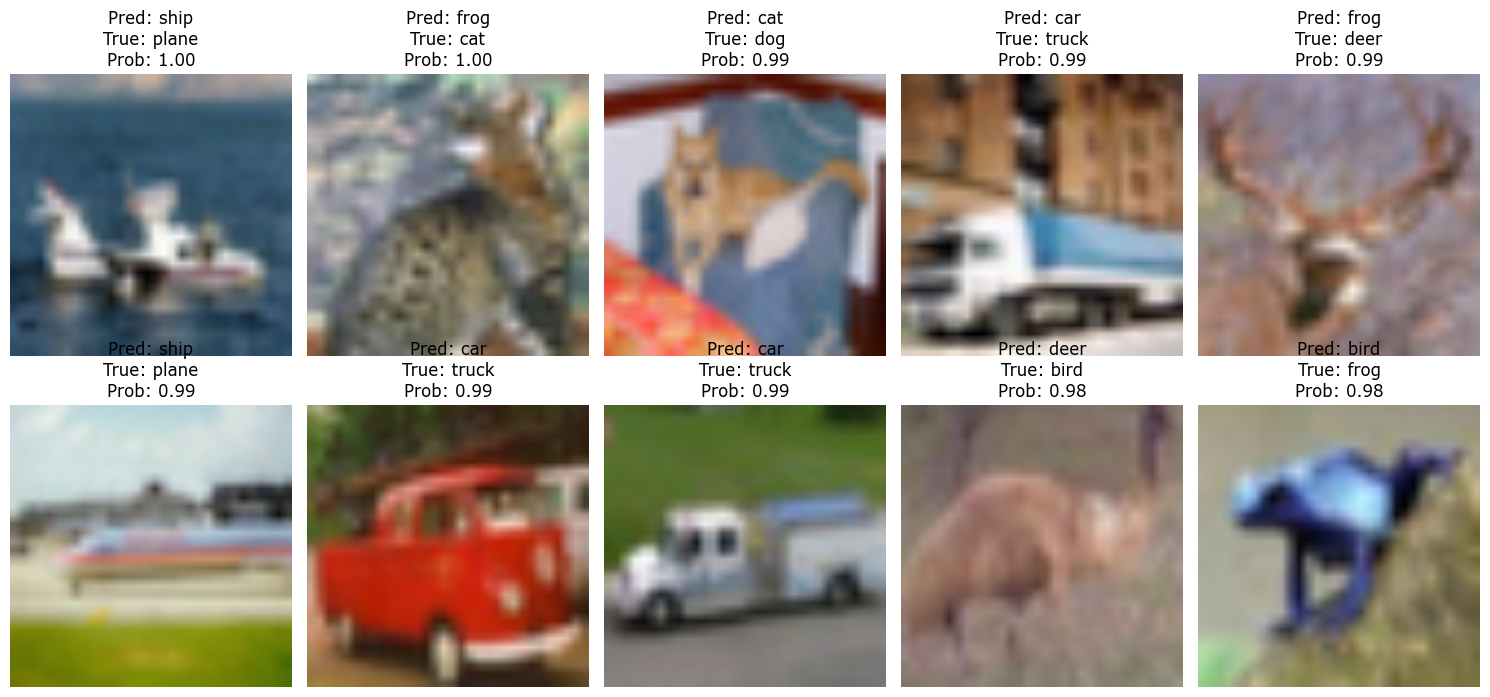

In [ ]:
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Metrics for storing misclassification data
errors = []

model.eval()
print("Searching for the most confident mistakes...")

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        
        # Convert logits to probabilities
        probs = F.softmax(outputs, dim=1)
        
        max_probs, predicted = torch.max(probs, 1)
        
        incorrect_mask = predicted != targets
        
        for i in range(len(targets)):
            if incorrect_mask[i]:
                errors.append({
                    'image': inputs[i].cpu(),      
                    'true_label': targets[i].item(),
                    'pred_label': predicted[i].item(),
                    'prob': max_probs[i].item()     
                })

# Sort errors by probability in descending order to find "blatant" mistakes
errors.sort(key=lambda x: x['prob'], reverse=True)
top_10_errors = errors[:10]

# --- Section I: Visualizing Top 10 Errors ---

def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor * std + mean
    return torch.clamp(tensor, 0, 1) 

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

for idx, error in enumerate(top_10_errors):
    img = denormalize(error['image'])
    img_np = img.numpy()
    img_np = np.transpose(img_np, (1, 2, 0)) 
    
    ax = axes[idx]
    ax.imshow(img_np)
    
    true_class_name = classes[error['true_label']]
    pred_class_name = classes[error['pred_label']]
    
    ax.set_title(f"Pred: {pred_class_name}\nTrue: {true_class_name}\nProb: {error['prob']:.2f}")
    ax.axis('off')

plt.tight_layout()
plt.show()

### Part J-K: Custom ResNet Implementation from Scratch
We implement a simplified ResNet architecture, including custom **Residual Blocks** with skip-connections. Unlike the previous approach, this model is trained from scratch, requiring a more extensive training process to reach the 70% accuracy threshold.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

# --- Section J: Building the Residual Block and Model ---

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()
        # First convolution: handles downsampling via stride
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        
        # Second convolution: maintains spatial dimensions
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        # Skip Connection (Shortcut)
        self.shortcut = nn.Sequential()
        # Adjusting shortcut dimensions to match output if stride > 1 or channel depth changes
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        # Element-wise addition of the shortcut connection before the final activation
        out += self.shortcut(x)
        out = F.relu(out)
        return out

class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super(CustomResNet, self).__init__()
        # Initial feature extraction layer
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)
        
        # Staged residual blocks with increasing filter depth and spatial downsampling
        self.layer1 = ResidualBlock(16, 32, stride=2)
        self.layer2 = ResidualBlock(32, 64, stride=2)
        self.layer3 = ResidualBlock(64, 128, stride=2)
        
        # Global Average Pooling to reduce spatial dimensions to 1x1
        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.adaptive_pool(out)
        out = out.view(out.size(0), -1) # Flattening for the linear layer
        out = self.fc(out)
        return out

# Model instantiation and device placement
custom_model = CustomResNet().to(device)

# --- Section K: Training the Scratch Model ---
criterion = nn.CrossEntropyLoss()
# Full parameter optimization for the custom architecture
optimizer_custom = optim.Adam(custom_model.parameters(), lr=0.001)

custom_epochs = 10 
print("Starting training for Custom ResNet...")

for epoch in range(custom_epochs):
    custom_model.train()
    running_loss = 0.0
    
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs, targets = inputs.to(device), targets.to(device)
        
        optimizer_custom.zero_grad()
        outputs = custom_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer_custom.step()
        
        running_loss += loss.item()
        if (batch_idx + 1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{custom_epochs}], Batch [{batch_idx+1}/{len(train_loader)}], Loss: {running_loss/100:.4f}")
            running_loss = 0.0
            
    # 
    test_accuracy = calculate_accuracy(test_loader, custom_model, device)
    print(f"--- Epoch {epoch+1} Summary: Custom Model Test Accuracy = {test_accuracy:.2f}% ---")
    
    if test_accuracy >= 70.0:
        print(f"Goal reached! Custom Model Accuracy is {test_accuracy:.2f}%, stopping training.")
        break

Starting training for Custom ResNet...
Epoch [1/10], Batch [100/782], Loss: 1.9986
Epoch [1/10], Batch [200/782], Loss: 1.8412
Epoch [1/10], Batch [300/782], Loss: 1.7211
Epoch [1/10], Batch [400/782], Loss: 1.6431
Epoch [1/10], Batch [500/782], Loss: 1.5506
Epoch [1/10], Batch [600/782], Loss: 1.5048
Epoch [1/10], Batch [700/782], Loss: 1.4621
--- Epoch 1 Summary: Custom Model Test Accuracy = 44.72% ---
Epoch [2/10], Batch [100/782], Loss: 1.3825
Epoch [2/10], Batch [200/782], Loss: 1.3419
Epoch [2/10], Batch [300/782], Loss: 1.3318
Epoch [2/10], Batch [400/782], Loss: 1.3011
Epoch [2/10], Batch [500/782], Loss: 1.3114
Epoch [2/10], Batch [600/782], Loss: 1.2684
Epoch [2/10], Batch [700/782], Loss: 1.2455
--- Epoch 2 Summary: Custom Model Test Accuracy = 55.68% ---
Epoch [3/10], Batch [100/782], Loss: 1.2087
Epoch [3/10], Batch [200/782], Loss: 1.1522
Epoch [3/10], Batch [300/782], Loss: 1.1714
Epoch [3/10], Batch [400/782], Loss: 1.1474
Epoch [3/10], Batch [500/782], Loss: 1.1328
Epo

In [ ]:
# Extended training loop to reach the target convergence threshold
print(f"Continuing training... Starting from current accuracy.")

for epoch in range(11, 16): 
    custom_model.train()
    running_loss = 0.0
    
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs, targets = inputs.to(device), targets.to(device)
        
        optimizer_custom.zero_grad()
        outputs = custom_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer_custom.step()
        
        running_loss += loss.item()
            
    # Monitoring final performance
    test_accuracy = calculate_accuracy(test_loader, custom_model, device)
    print(f"--- Epoch {epoch} Summary: Custom Model Test Accuracy = {test_accuracy:.2f}% ---")
    
    if test_accuracy >= 70.0:
        print(f"Goal reached! Accuracy is {test_accuracy:.2f}%, stopping training.")
        break

Continuing training... Starting from current accuracy.
--- Epoch 11 Summary: Custom Model Test Accuracy = 61.01% ---
--- Epoch 12 Summary: Custom Model Test Accuracy = 71.04% ---
Goal reached! Accuracy is 71.04%, stopping training.


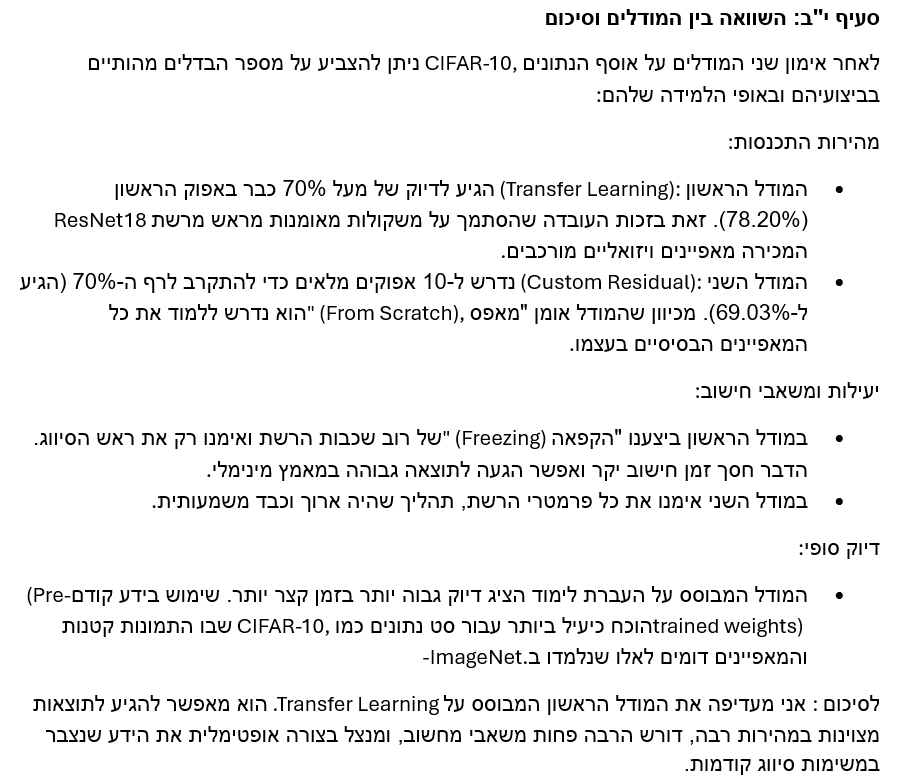